In [128]:
#Importing libraries
%pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 


#Sets size for rendering
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

#For rendering visualisations below code cell within notebook and not external
%matplotlib inline


#Load data set
df = pd.read_csv('urbandata.csv')

#Checkout info of the loaded data
df.info()
df.describe(include='all').round(2)

Note: you may need to restart the kernel to use updated packages.
<class 'pandas.DataFrame'>
RangeIndex: 456 entries, 0 to 455
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   inspector_id           456 non-null    int64  
 1   material_flexibility   456 non-null    float64
 2   structural_mass_ratio  455 non-null    float64
 3   recent_precipitation   454 non-null    float64
 4   infrastructure_age     452 non-null    float64
 5   surface_debris         456 non-null    float64
 6   vibration_exposure     455 non-null    float64
 7   asset_density          456 non-null    float64
 8   inspection_season      456 non-null    str    
 9   inspection_window      456 non-null    str    
 10  moisture_stress        453 non-null    float64
 11  failure                456 non-null    int64  
dtypes: float64(8), int64(2), str(2)
memory usage: 42.9 KB



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
count,456.00,456.00,455.00,454.00,452.00,456.00,455.00,456.00,456,456,453.00,456.00
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,4,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,summer,night,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,133,172,NaN,NaN
mean,5.73,32.59,12.09,3.11,68.53,9.27,4.96,2.65,NaN,NaN,0.04,0.37
std,2.92,4.74,0.59,1.37,14.49,0.79,0.08,0.27,NaN,NaN,0.05,0.48
min,1.00,24.92,11.51,0.00,41.09,7.43,4.74,2.20,NaN,NaN,0.00,0.00
25%,3.00,30.50,11.67,2.14,58.59,8.74,4.91,2.45,NaN,NaN,0.01,0.00
50%,6.00,31.90,11.86,2.93,64.79,9.13,4.96,2.60,NaN,NaN,0.02,0.00
75%,8.00,34.03,12.33,4.31,76.74,9.77,5.01,2.85,NaN,NaN,0.04,1.00


In [98]:
df.head()

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
0,5,31.762605,12.891996,4.711064,71.480592,9.429642,5.177088,2.9944,summer,afternoon,0.06,1
1,7,30.770158,11.835563,3.315888,60.300892,8.655641,4.927622,2.6808,spring,morning,0.01,0
2,6,31.591296,11.738267,2.425562,56.367965,9.017137,4.910945,2.5294,autumn,night,0.02,0
3,5,30.834649,11.622881,2.164486,53.135138,8.864650,4.949554,2.4810,autumn,afternoon,0.02,1
4,2,33.315981,12.616065,4.557082,77.482269,9.549344,5.047689,3.0460,summer,morning,0.07,1


In [99]:
df.tail()


,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
451,5,30.154152,11.816298,2.120903,57.140895,8.778138,5.030630,2.53112,spring,afternoon,0.00,0
452,10,32.254170,11.779914,2.841949,61.490869,9.300330,4.930623,2.56308,autumn,night,0.02,0
453,6,28.465334,11.506094,0.000000,62.438486,8.169076,4.743956,2.20000,winter,afternoon,0.04,0
454,9,31.813525,12.015377,3.655757,54.803893,9.256184,4.990145,2.84280,summer,night,0.06,1
455,8,28.606663,11.644398,2.448486,55.749547,8.316101,5.010208,2.46112,winter,night,0.00,0


In [100]:
df.shape

(456, 12)

So far I've just checked the overal table's info - what columns and variables (and their types) are included and so forth

In [101]:
print(f"Duplicate rows: {df.duplicated().sum()}") #checking for duplicate rows jsut incase that needed to be cleaned later
print(f"Missing values: {df.isnull().sum().sum()}") #checking for missing values that will need to be cleaned later


Duplicate rows: 0
Missing values: 11


In [102]:
print(f" infrastructure age  range    : {df['infrastructure_age'].min()} → {df['infrastructure_age'].max()}") #checking infrastructure age range as i think this will be important 

 infrastructure age  range    : 41.0876022216893 → 125.94955152489


Target and Feature Variables

In [103]:
#Target variable - failure
#thats what our outcome we are looking for is so it makes sense to use that as our target value.


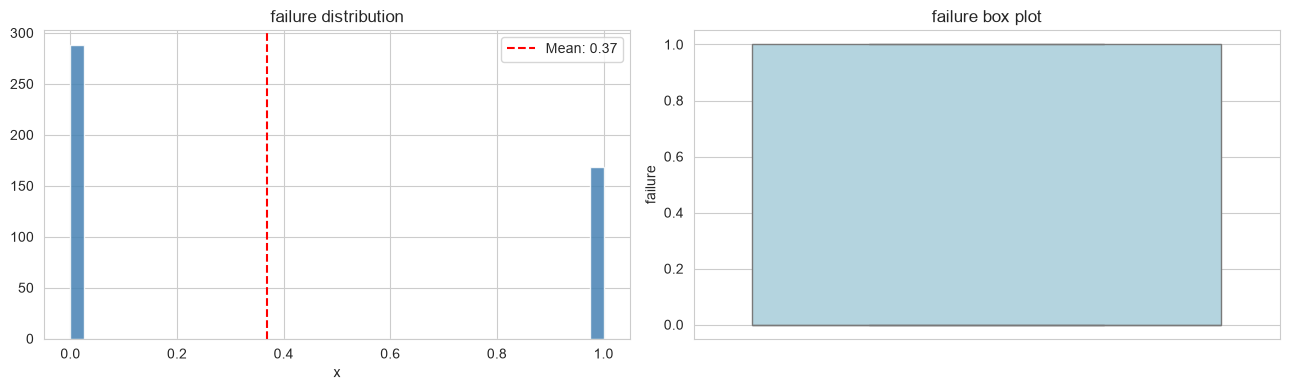

Skewness: 0.55
Range   : 0.00 → 1.00


In [104]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["failure"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(df["failure"].mean(), color="red", linestyle="--",
                label=f"Mean: {df['failure'].mean():.2f}")
axes[0].set_title("failure distribution"); axes[0].set_xlabel("x"); axes[0].legend()

sns.boxplot(y=df["failure"], ax=axes[1], color="lightblue")
axes[1].set_title("failure box plot")
plt.tight_layout(); plt.show()
print(f"Skewness: {df['failure'].skew():.2f}")
print(f"Range   : {df['failure'].min():.2f} → {df['failure'].max():.2f}")


A histogram and a box plot wasnt the best for this target variable. A barchart seems like a better option as theres only two outcomes 1 and 0 so there isnt much of a distribution to show.


In [105]:
df["failure"].value_counts()


failure
0    288
1    168
Name: count, dtype: int64

In [106]:
#more non failures

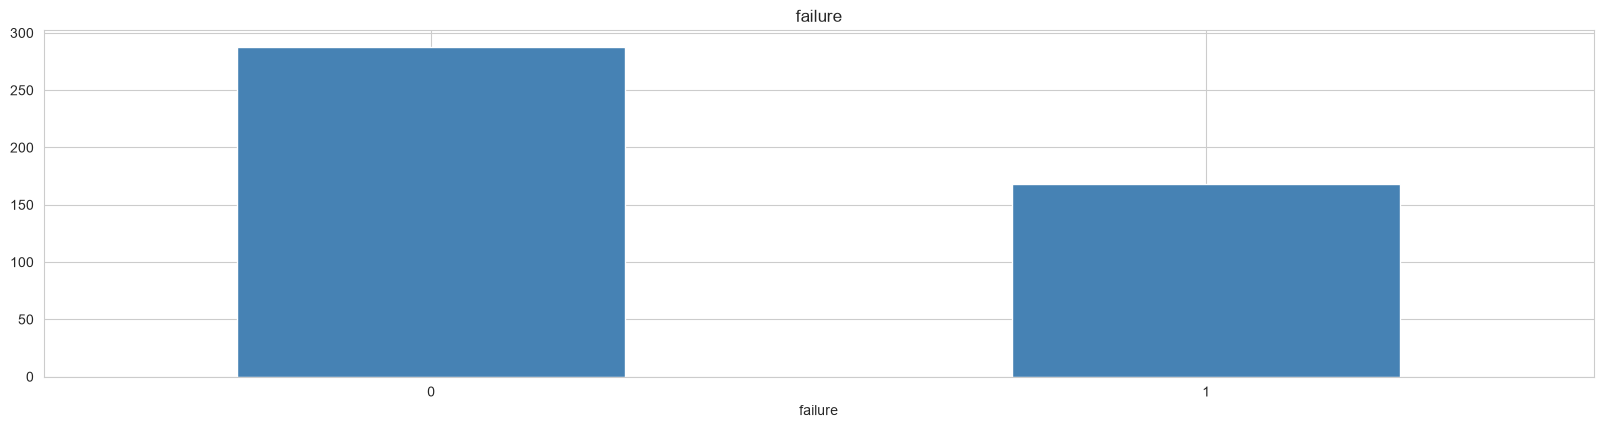

In [107]:
fig, axes = plt.subplots(1, 1, figsize=(20, 4.5))
df["failure"].value_counts().plot(kind="bar", color="steelblue", ax=axes)
axes.set_title("failure"); axes.tick_params(axis="x", rotation=0)


In [108]:
#Features

Univariate Numerical Features

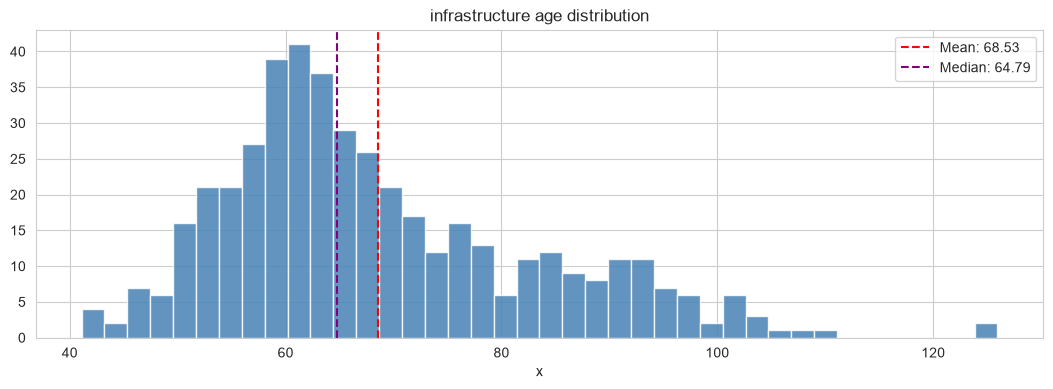

In [109]:
fig, axes = plt.subplots(1, 1, figsize=(13, 4))
axes.hist(df["infrastructure_age"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes.axvline(df["infrastructure_age"].mean(), color="red", linestyle="--",
                label=f"Mean: {df['infrastructure_age'].mean():.2f}")
axes.axvline(df["infrastructure_age"].median(), color="purple", linestyle="--",
                label=f"Median: {df['infrastructure_age'].median():.2f}")
axes.set_title("infrastructure age distribution"); axes.set_xlabel("x"); axes.legend()

more of a right skew

In [110]:
print(f"Skew is {df["infrastructure_age"].skew().round(2)}")

Skew is 0.88


Deffo a right skew

In [111]:
#making simple subplots for all the numerical features no ive made a detailed one.

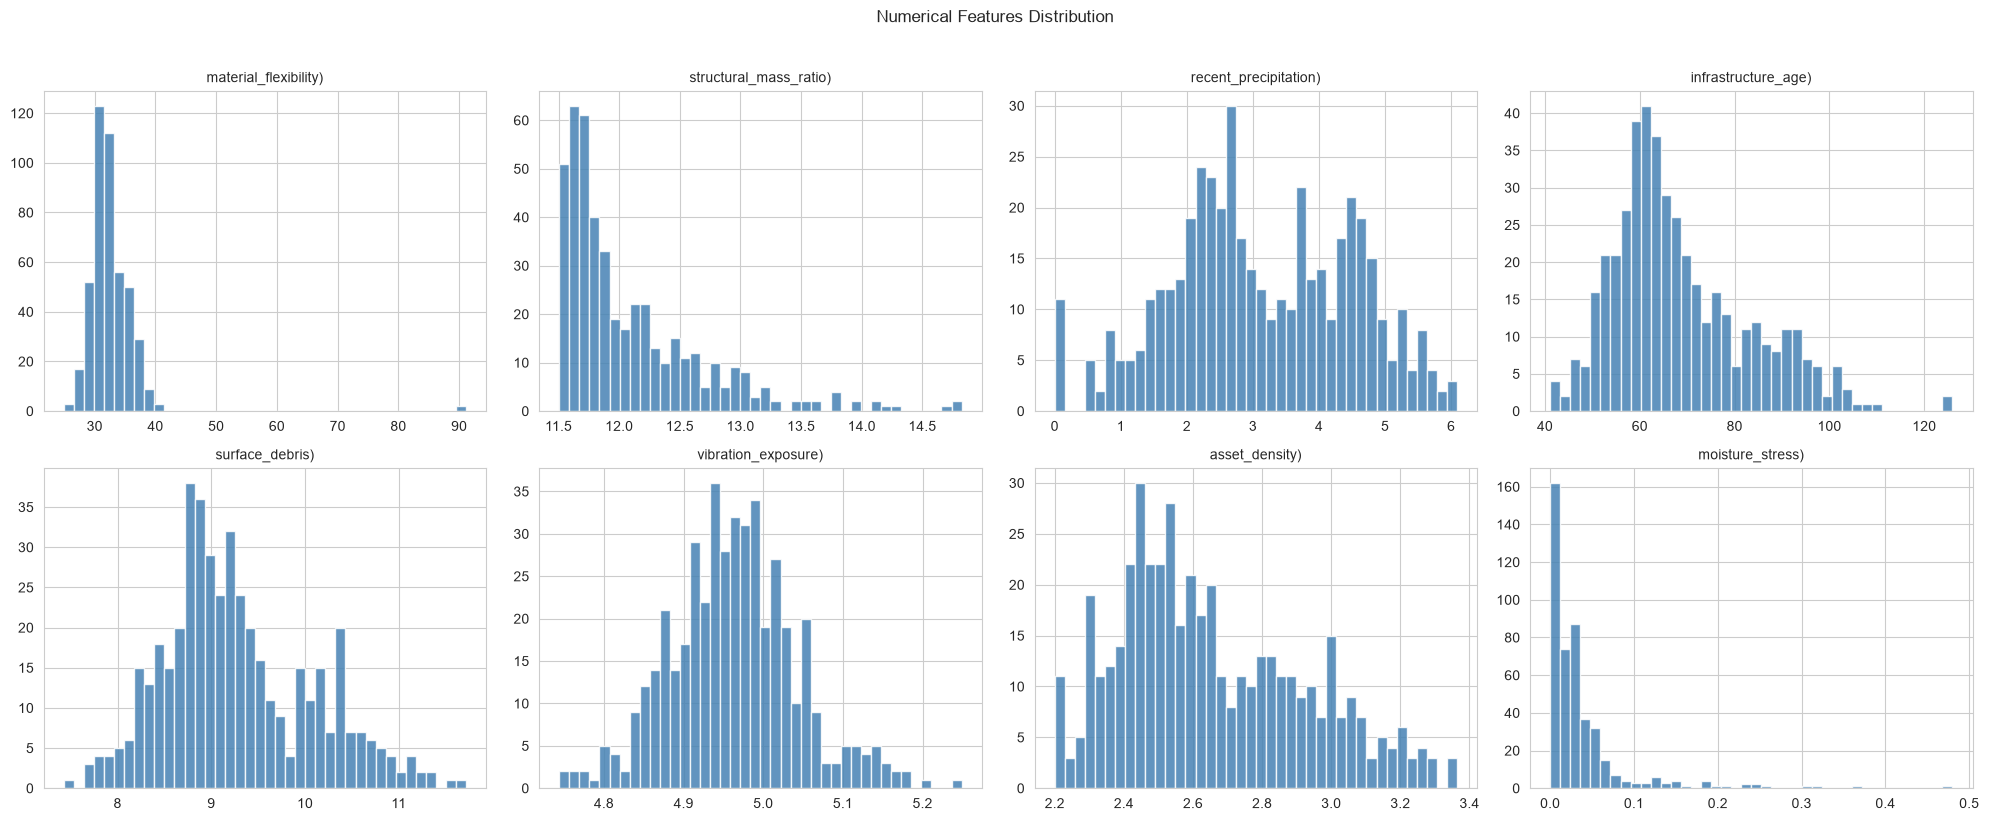

material_flexibility     8.36
structural_mass_ratio    1.76
recent_precipitation    -0.06
infrastructure_age       0.88
surface_debris           0.55
vibration_exposure       0.24
asset_density            0.54
moisture_stress          3.92
dtype: float64


In [112]:
volume_cols = ["material_flexibility","structural_mass_ratio","recent_precipitation","infrastructure_age","surface_debris","vibration_exposure","asset_density","moisture_stress"]
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()
for i, col in enumerate(volume_cols):
    (df[col]).hist(bins=40, color="steelblue", edgecolor="white", alpha=0.85, ax=axes[i])
    axes[i].set_title(f"{col})", fontsize=10)
plt.suptitle("Numerical Features Distribution", y=1.02)
plt.tight_layout(); plt.show()
print(df[volume_cols].skew().round(2))


material_flexibility, structural_mass_ratio and moisture_stress have very extreme right skews.


In [113]:
#further dive into material_flexibility, structural_mass_ratio and moisture_stress

In [114]:
df[['material_flexibility','structural_mass_ratio','moisture_stress']].describe().round(2)

,material_flexibility,structural_mass_ratio,moisture_stress
count,456.00,455.00,453.00
mean,32.59,12.09,0.04
std,4.74,0.59,0.05
min,24.92,11.51,0.00
25%,30.50,11.67,0.01
50%,31.90,11.86,0.02
75%,34.03,12.33,0.04
max,91.16,14.82,0.48


Skewness: 3.92
Range   : 0.00 → 0.48
Skewness: 1.76
Range   : 11.51 → 14.82
Skewness: 8.36
Range   : 24.92 → 91.16


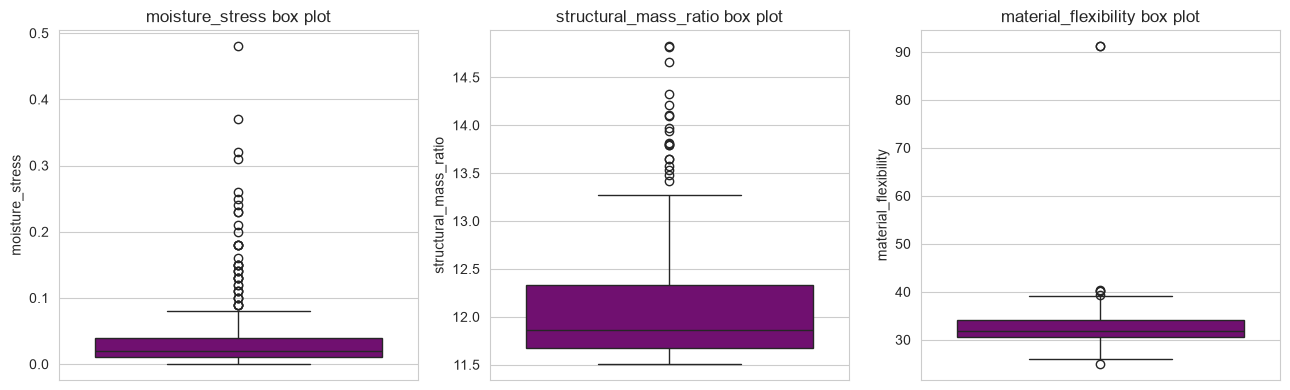

In [115]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sns.boxplot(y=df["moisture_stress"], ax=axes[0], color="purple")
axes[0].set_title("moisture_stress box plot")
print(f"Skewness: {df['moisture_stress'].skew():.2f}")
print(f"Range   : {df['moisture_stress'].min():.2f} → {df['moisture_stress'].max():.2f}")

sns.boxplot(y=df['structural_mass_ratio'], ax=axes[1], color="purple")
axes[1].set_title("structural_mass_ratio box plot")
print(f"Skewness: {df['structural_mass_ratio'].skew():.2f}")
print(f"Range   : {df['structural_mass_ratio'].min():.2f} → {df['structural_mass_ratio'].max():.2f}")

sns.boxplot(y=df['material_flexibility'], ax=axes[2], color="purple")
axes[2].set_title("material_flexibility box plot")
print(f"Skewness: {df['material_flexibility'].skew():.2f}")
print(f"Range   : {df['material_flexibility'].min():.2f} → {df['material_flexibility'].max():.2f}")

plt.tight_layout(); plt.show()

In [116]:
df["material_flexibility"].nlargest(10)

9      91.157913
421    91.157913
161    40.452981
143    40.165117
407    40.080371
79     39.429438
266    39.198270
308    38.925162
125    38.745914
63     38.388974
Name: material_flexibility, dtype: float64

Very large values which are bringing the average up, they may be outliers that need to be cleaned later.

In [117]:
df.nlargest(5, "material_flexibility")

,inspector_id,material_flexibility,structural_mass_ratio,recent_precipitation,infrastructure_age,surface_debris,vibration_exposure,asset_density,inspection_season,inspection_window,moisture_stress,failure
9,2,91.157913,12.004540,2.661193,55.022194,8.960423,4.858190,2.55912,winter,night,0.01,0
421,5,91.157913,12.053391,3.817170,64.528942,9.192685,4.953214,2.68840,winter,afternoon,0.01,0
161,7,40.452981,13.817771,5.649279,125.328825,10.895086,4.920565,2.83800,autumn,night,0.02,1
143,1,40.165117,14.210407,5.757190,125.949552,11.719278,4.904398,3.25000,autumn,morning,0.07,1
407,7,40.080371,13.533455,5.957985,97.304482,11.372613,5.013988,3.27520,spring,night,0.06,1


In [118]:
df.loc[df["material_flexibility"] > 40, "material_flexibility"].value_counts() #checking how many are over 40

material_flexibility
91.157913    2
40.165117    1
40.452981    1
40.080371    1
Name: count, dtype: int64

In [119]:
df.loc[df["material_flexibility"] > 80,
       ["material_flexibility", "failure"]]

,material_flexibility,failure
9,91.157913,0
421,91.157913,0


Both extreme values are non failiures. Still seems suspicious, could be outliers

In [121]:
df.groupby("inspection_season")["material_flexibility"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
inspection_season,,,,,,,,
autumn,122.0,32.22,2.74,26.63,30.44,31.60,33.69,40.45
spring,85.0,31.66,2.55,24.92,30.31,31.43,32.67,40.08
sumer,1.0,33.05,NaN,33.05,33.05,33.05,33.05,33.05
summer,133.0,34.04,2.48,27.68,32.14,34.05,36.04,39.20
winter,115.0,31.99,8.13,26.04,29.78,31.09,32.07,91.16


Theres an error in this. "sumer" needs to be deletd. Std for winter is very high...when everything else is normal except max.

In [122]:
df["inspection_season"].value_counts() #just comfirming error

inspection_season
summer    133
autumn    122
winter    115
spring     85
sumer       1
Name: count, dtype: int64

Univariate Categorical features

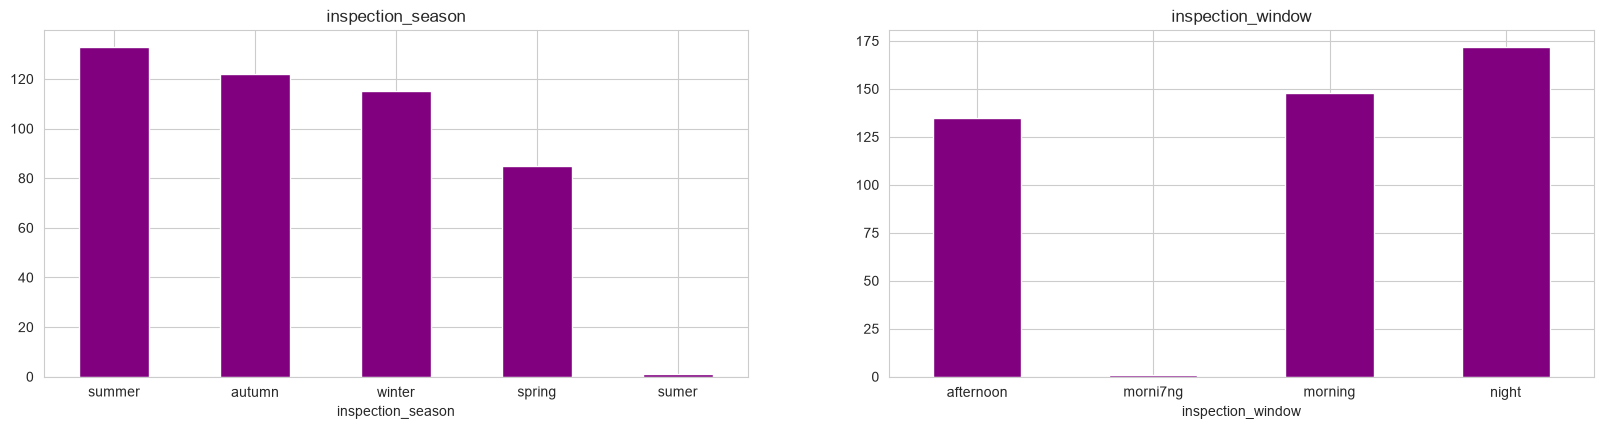

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(20, 4.5))
df["inspection_season"].value_counts().plot(kind="bar", color="purple", ax=axes[0])
axes[0].set_title("inspection_season"); axes[0].tick_params(axis="x", rotation=0)

df["inspection_window"].value_counts().sort_index().plot(kind="bar", color="purple", ax=axes[1])
axes[1].set_title("inspection_window"); axes[1].tick_params(axis="x", rotation=0)

Comfirmed season error 'sumer' and uncovered a new error, 'morni7ng' both will need to be cleaned.

In [124]:
df["inspection_window"].value_counts() #just comfirming error

inspection_window
night        172
morning      148
afternoon    135
morni7ng       1
Name: count, dtype: int64

Bivariate Features

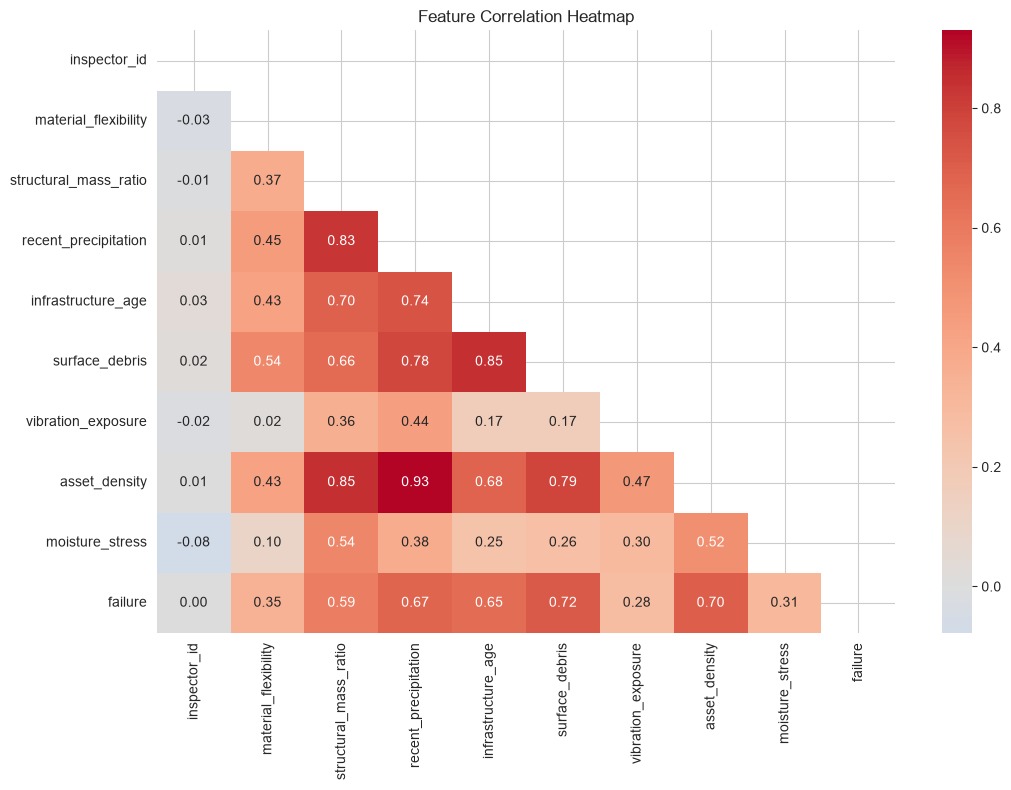

In [133]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout();plt.show()


Key EDA Findings

1) 11 missing values, no duplicates
2) material_flexibility, structural_mass_ratio and moisture_stress have the highest right skews
3) material_flexibility has the highest right skew at 8.36 due to two very high values which could be treated as outliers
4) Two spelling mistakes in categorical features inspection_season and inspection_window 'sumer' and 'morn7ng'
5) Highest correlation with target variable is surface_debris at 0.72.